# Global Clustering Project (Machine Learning + Streamlit)

Groups the countries of the world by their development data using **PCA, KMeans and DBSCAN**,
and shows a **Streamlit app** where you can select countries and see their GDP for every year.

**How to run this notebook:** click `Runtime` > `Run all` and wait about 2 to 3 minutes.
At the very end, a link will be printed. Open that link to see the Streamlit app.

**Files created by this notebook** (you can see them in the left side `Files` panel):
`requirements.txt`, `app.py`, `country_results.csv` and the `.pkl` model files.

## Step 0: Setup
First we create the `requirements.txt` file and install the libraries.

In [1]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
scikit-learn
openpyxl
streamlit


Overwriting requirements.txt


In [2]:
!pip -q install -r requirements.txt


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Get the data file
The notebook downloads the Excel file from GitHub.
If the download does not work, it asks you to upload `World_development_mesurement.xlsx` from your computer.

In [3]:
import os
import urllib.request

DATA_FILE = "World_development_mesurement.xlsx"

# GitHub "raw" link of the Excel file (change this to your own link)
DATA_URL = "https://raw.githubusercontent.com/ajithkumar564/global-clustering-project/main/World_development_mesurement.xlsx"

if os.path.exists(DATA_FILE):
    print("Data file is already here.")
else:
    try:
        urllib.request.urlretrieve(DATA_URL, DATA_FILE)
        print("Data file downloaded.")
    except Exception:
        print("Could not download. Please upload the Excel file now.")
        from google.colab import files
        files.upload()

Data file is already here.


## Step 1: Import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

## Step 2: Load the data

In [5]:
data = pd.read_excel("World_development_mesurement.xlsx")
data.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Country,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,0.020,NaN,87931.0,Algeria,NaN,NaN,26998.0,"$54,790,058,957",0.035,$60,...,67.0,0.0,1,0.342,0.619,0.039,31719449,0.599,"$102,000,000","$193,000,000"
1,0.050,NaN,9542.0,Angola,NaN,NaN,7499.0,"$9,129,594,819",0.034,$22,...,44.0,0.0,1,0.476,0.499,0.025,13924930,0.324,"$34,000,000","$146,000,000"
2,0.043,NaN,1617.0,Benin,NaN,NaN,1983.0,"$2,359,122,303",0.043,$15,...,53.0,0.0,1,0.454,0.517,0.029,6949366,0.383,"$77,000,000","$50,000,000"
3,0.027,NaN,4276.0,Botswana,NaN,NaN,1836.0,"$5,788,311,645",0.047,$152,...,49.0,0.1,1,0.383,0.587,0.029,1755375,0.532,"$227,000,000","$209,000,000"
4,0.046,NaN,1041.0,Burkina Faso,NaN,NaN,NaN,"$2,610,959,139",0.051,$12,...,49.0,0.0,1,0.468,0.505,0.028,11607944,0.178,"$23,000,000","$30,000,000"


In [6]:
# Check rows, columns and data types
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   str    
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   str    
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   str    
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   str    
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   float64
 15

In [7]:
# Quick statistics of the number columns
data.describe()

,Birth Rate,CO2 Emissions,Days to Start Business,Ease of Business,Energy Usage,Health Exp % GDP,Hours to do Tax,Infant Mortality Rate,Internet Usage,Lending Interest,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban
count,2585.000000,2.125000e+03,1718.000000,185.000000,1.785000e+03,2395.000000,1416.000000,2444.000000,2531.000000,1880.000000,2568.000000,2568.000000,2537.000000,2704.0,2484.000000,2484.000000,2484.000000,2.704000e+03,2678.000000
mean,0.022715,1.423071e+05,39.999418,94.875676,7.723684e+04,0.064170,302.068503,0.032813,0.239747,0.148103,71.159268,66.461838,0.578124,1.0,0.303051,0.623481,0.073465,3.145729e+07,0.562953
std,0.011338,6.159288e+05,57.318588,54.791906,2.599239e+05,0.026325,273.299686,0.029968,0.260132,0.171829,10.708262,9.390217,0.474647,0.0,0.106577,0.069660,0.049541,1.242894e+08,0.245897
min,0.007000,7.000000e+00,1.000000,1.000000,8.000000e+00,0.008000,12.000000,0.002000,0.000000,0.005000,39.000000,37.000000,0.000000,1.0,0.118000,0.474000,0.003000,1.887600e+04,0.082000
25%,0.013000,1.360000e+03,13.000000,48.000000,3.737000e+03,0.046000,156.000000,0.009000,0.000000,0.080000,64.000000,61.000000,0.100000,1.0,0.204750,0.559000,0.033000,8.783360e+05,0.356000
50%,0.020000,8.529000e+03,26.000000,94.000000,1.433800e+04,0.061000,239.000000,0.020000,0.100000,0.120000,75.000000,69.000000,0.500000,1.0,0.299500,0.642500,0.052000,5.800324e+06,0.560000
75%,0.031000,5.910800e+04,45.000000,142.000000,4.185200e+04,0.079000,344.750000,0.053000,0.400000,0.173000,79.000000,73.250000,0.900000,1.0,0.402000,0.676000,0.112000,2.014089e+07,0.765000
max,0.053000,8.286892e+06,694.000000,189.000000,2.727728e+06,0.225000,2600.000000,0.141000,1.000000,4.965000,87.000000,88.000000,2.900000,1.0,0.500000,0.858000,0.244000,1.350695e+09,1.000000


## Step 3: Keep Country and Year separate
Country and Year are only labels, so we do not use them for clustering.

The Excel file has no Year column, but the rows are in year order (2000, 2001, 2002 ...).
So the 1st time a country appears is 2000, the 2nd time is 2001, and so on.

In [8]:
country = data["Country"]

# Make the Year column
year = 2000 + data.groupby("Country").cumcount()

# Remove Country from the data used for clustering
data = data.drop("Country", axis=1)

In [9]:
# Check: every year should have the same number of rows (one row per country)
print(year.value_counts().sort_index())

2000    208
2001    208
2002    208
2003    208
2004    208
2005    208
2006    208
2007    208
2008    208
2009    208
2010    208
2011    208
2012    208
Name: count, dtype: int64


## Step 4: Clean the data
Some columns have text like `$54,790,058,957` or `41%`. We remove `$`, `,` and `%` and change them to numbers.

In [10]:
for col in data.columns:

    # Only clean the columns that are not numbers yet
    if not pd.api.types.is_numeric_dtype(data[col]):

        data[col] = data[col].astype(str).str.replace("%", "", regex=False)
        data[col] = data[col].str.replace("$", "", regex=False)
        data[col] = data[col].str.replace(",", "", regex=False)

        # Change text to number. If it is not possible, it becomes NaN (missing)
        data[col] = pd.to_numeric(data[col], errors="coerce")

data.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,0.020,NaN,87931.0,NaN,NaN,26998.0,5.479006e+10,0.035,60.0,NaN,...,67.0,0.0,1,0.342,0.619,0.039,31719449,0.599,102000000.0,193000000.0
1,0.050,NaN,9542.0,NaN,NaN,7499.0,9.129595e+09,0.034,22.0,NaN,...,44.0,0.0,1,0.476,0.499,0.025,13924930,0.324,34000000.0,146000000.0
2,0.043,NaN,1617.0,NaN,NaN,1983.0,2.359122e+09,0.043,15.0,NaN,...,53.0,0.0,1,0.454,0.517,0.029,6949366,0.383,77000000.0,50000000.0
3,0.027,NaN,4276.0,NaN,NaN,1836.0,5.788312e+09,0.047,152.0,NaN,...,49.0,0.1,1,0.383,0.587,0.029,1755375,0.532,227000000.0,209000000.0
4,0.046,NaN,1041.0,NaN,NaN,NaN,2.610959e+09,0.051,12.0,NaN,...,49.0,0.0,1,0.468,0.505,0.028,11607944,0.178,23000000.0,30000000.0


## Step 5: Fill missing values
First we save the real GDP (with missing values) for the Streamlit app.
Then we fill the missing values with the **median** of each column.

In [11]:
# Save the real GDP before filling (the app should not show made-up GDP)
gdp_original = data["GDP"].copy()

# Replace infinite values with missing values
data = data.replace([np.inf, -np.inf], np.nan)

# Fill missing values with the median of each column
data = data.fillna(data.median())

# Check: should be 0 for every column
print(data.isnull().sum())

Birth Rate                0
Business Tax Rate         0
CO2 Emissions             0
Days to Start Business    0
Ease of Business          0
Energy Usage              0
GDP                       0
Health Exp % GDP          0
Health Exp/Capita         0
Hours to do Tax           0
Infant Mortality Rate     0
Internet Usage            0
Lending Interest          0
Life Expectancy Female    0
Life Expectancy Male      0
Mobile Phone Usage        0
Number of Records         0
Population 0-14           0
Population 15-64          0
Population 65+            0
Population Total          0
Population Urban          0
Tourism Inbound           0
Tourism Outbound          0
dtype: int64


## Step 6: Correlation heatmap
This shows which columns are related to each other.

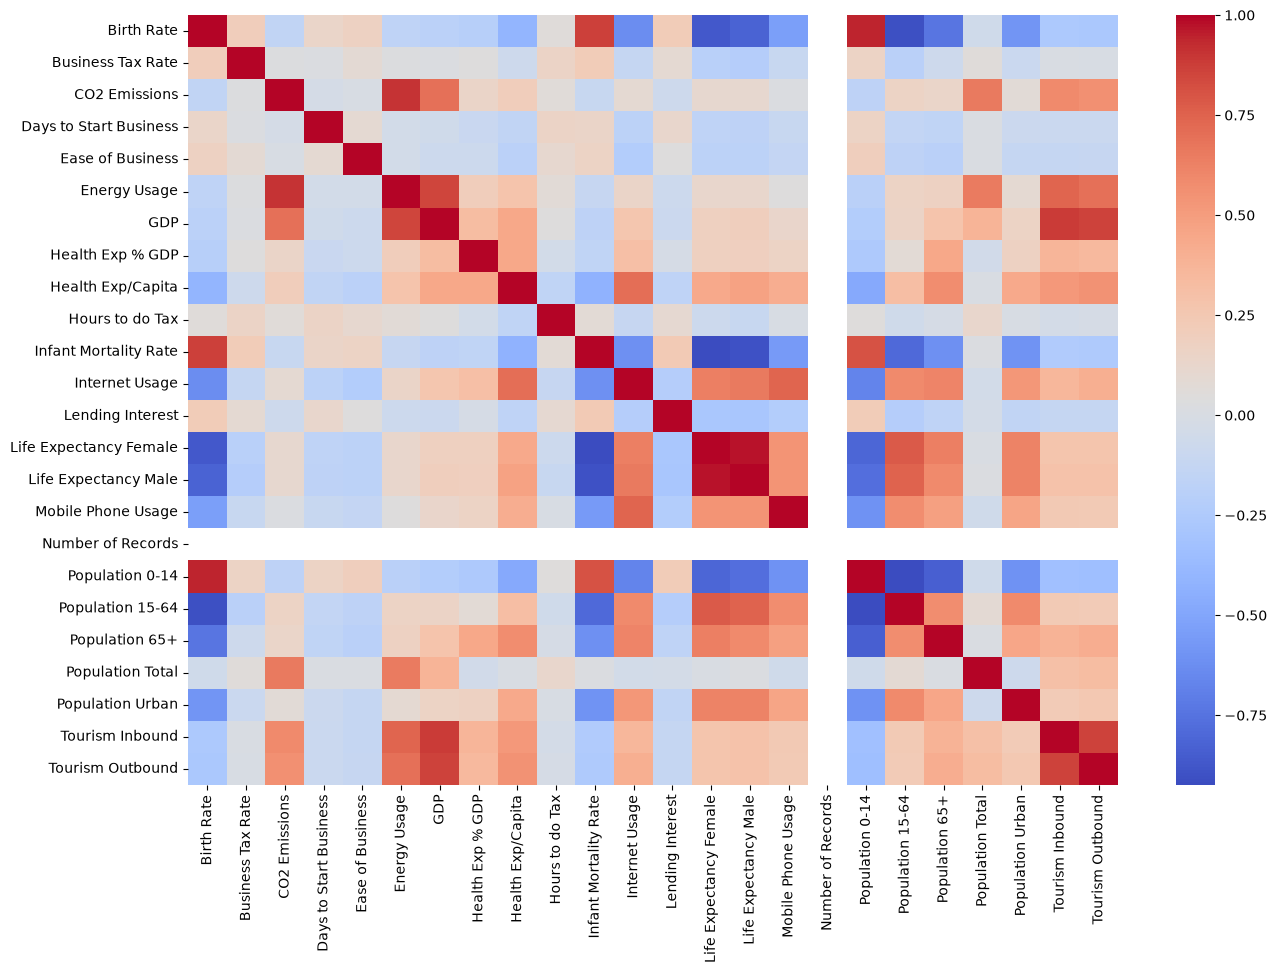

In [12]:
plt.figure(figsize=(15, 10))
sns.heatmap(data.corr(numeric_only=True), cmap="coolwarm")
plt.show()

## Step 7: Scale the data
Columns like GDP are very big and Birth Rate is very small. StandardScaler brings all columns to the same scale.

In [13]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

## Step 8: PCA
PCA reduces the number of columns but keeps 90% of the information.

In [14]:
pca = PCA(n_components=0.9)
x_pca = pca.fit_transform(scaled_data)

print("Original columns:", scaled_data.shape[1])
print("Columns after PCA:", x_pca.shape[1])

Original columns: 24
Columns after PCA: 11


In [15]:
explained_variance = pca.explained_variance_ratio_
print("Explained variance ratio:", explained_variance)
print("Total variance covered:", np.sum(explained_variance))

Explained variance ratio: [0.37399241 0.17196794 0.07037986 0.0545047  0.04280894 0.04141713
 0.03820013 0.03327491 0.03256634 0.02880622 0.02362442]
Total variance covered: 0.911542989417128


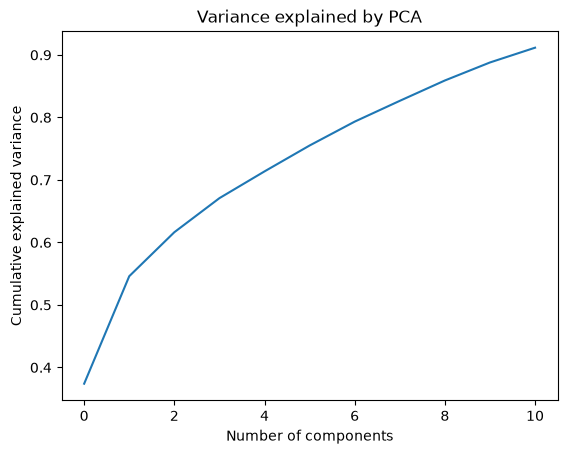

In [16]:
plt.plot(np.cumsum(explained_variance))
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Variance explained by PCA")
plt.show()

In [ ]:
plt.scatter(x_pca[:, 0], x_pca[:, 1])
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("PCA projection in 2D")
plt.show()

## Step 9: KMeans clustering
**Elbow method:** we try 1 to 10 clusters and look for the point where the line bends like an elbow.

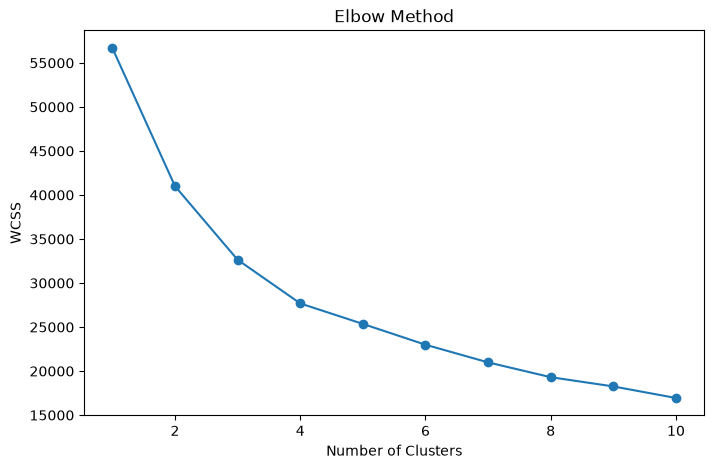

In [17]:
wcss = []

for i in range(1, 11):
    # n_init=10 is written on purpose, so the result is the same on every sklearn version
    model = KMeans(n_clusters=i, n_init=10, random_state=42)
    model.fit(x_pca)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [18]:
# Final KMeans model with 3 clusters
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(x_pca)

data["Cluster_KMeans"] = kmeans_labels
data["Cluster_KMeans"].value_counts()

Cluster_KMeans
2    1623
0    1055
1      26
Name: count, dtype: int64

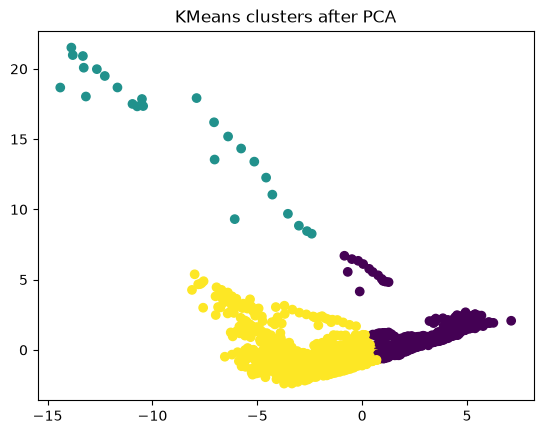

In [19]:
plt.scatter(x_pca[:, 0], x_pca[:, 1], c=kmeans_labels)
plt.title("KMeans clusters after PCA")
plt.show()

## Step 10: DBSCAN clustering
**K-distance graph:** helps to choose the `eps` value (the place where the line goes up sharply).

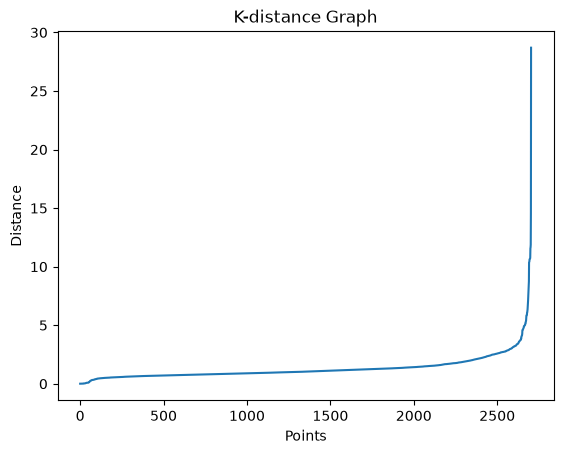

In [20]:
neighbors = NearestNeighbors(n_neighbors=10)
neighbors.fit(x_pca)
distances, indices = neighbors.kneighbors(x_pca)

distances = np.sort(distances[:, 9])
plt.plot(distances)
plt.xlabel("Points")
plt.ylabel("Distance")
plt.title("K-distance Graph")
plt.show()

**Tuning:** we try many `eps` and `min_samples` values and keep the one with the best silhouette score.

In [21]:
eps_values = [1.0, 1.2, 1.3, 1.4, 1.5, 1.7, 1.9, 2.0]
min_sample_range = range(1, 20)
output = []

for eps_val in eps_values:
    for min_samp in min_sample_range:
        labels = DBSCAN(eps=eps_val, min_samples=min_samp).fit(x_pca).labels_

        # Silhouette score needs at least 2 groups, so skip the bad combinations
        if len(set(labels)) < 2 or len(set(labels)) > len(labels) - 1:
            continue

        score = silhouette_score(x_pca, labels)
        output.append([eps_val, min_samp, score])

df_results = pd.DataFrame(output, columns=["eps", "min_samples", "score"])
df_results.sort_values("score", ascending=False).head()

,eps,min_samples,score
148,2.0,16,0.417366
147,2.0,15,0.415643
149,2.0,17,0.414076
150,2.0,18,0.412790
151,2.0,19,0.410431


In [22]:
best = df_results.sort_values("score", ascending=False).iloc[0]
best_eps = best["eps"]
best_min_samples = int(best["min_samples"])
best_score = best["score"]

print(f"Best parameters: eps={best_eps}, min_samples={best_min_samples}, score={best_score:.4f}")

Best parameters: eps=2.0, min_samples=16, score=0.4174


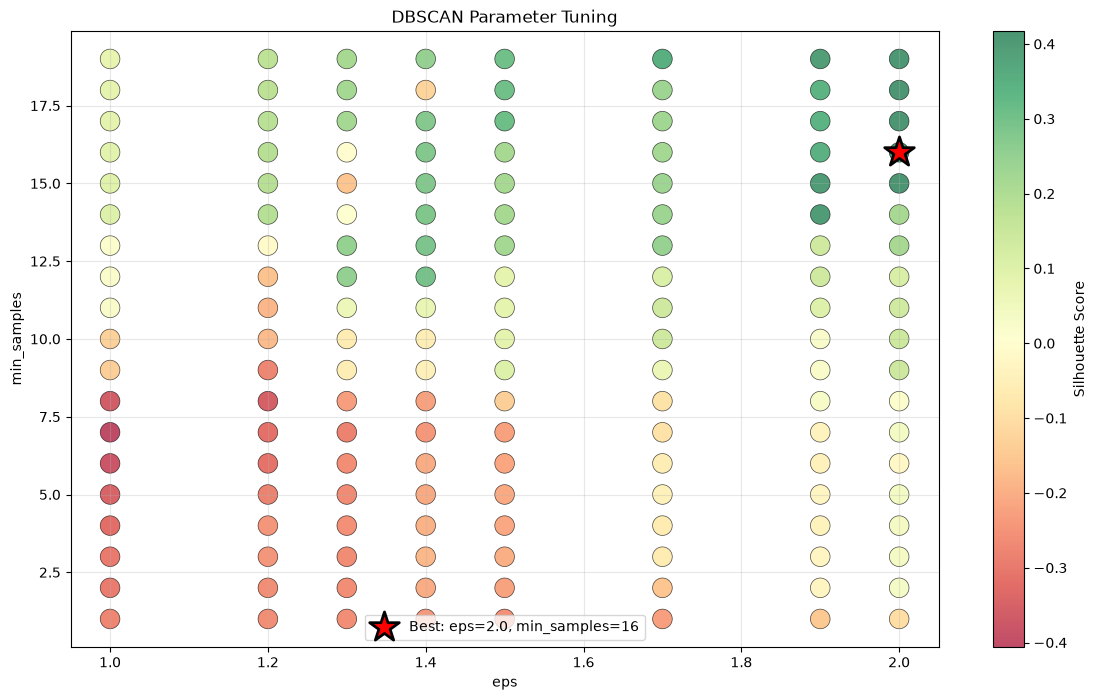

In [23]:
plt.figure(figsize=(14, 8))

scatter = plt.scatter(df_results["eps"], df_results["min_samples"],
                      c=df_results["score"], cmap="RdYlGn",
                      s=200, alpha=0.7, edgecolors="black", linewidth=0.5)

# Mark the best point with a star
plt.scatter([best_eps], [best_min_samples], color="red", s=500, marker="*",
            edgecolors="black", linewidth=2,
            label=f"Best: eps={best_eps}, min_samples={best_min_samples}", zorder=5)

plt.xlabel("eps")
plt.ylabel("min_samples")
plt.title("DBSCAN Parameter Tuning")
plt.colorbar(scatter, label="Silhouette Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [24]:
# Final DBSCAN model with the best parameters
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
dbscan_labels = dbscan.fit_predict(x_pca)

data["Cluster_DBScan"] = dbscan_labels
data["Cluster_DBScan"].value_counts()   # -1 means noise (outliers)

Cluster_DBScan
 0    2391
-1     313
Name: count, dtype: int64

## Step 11: Compare KMeans and DBSCAN

In [25]:
kmeans_score = silhouette_score(x_pca, kmeans_labels)
dbscan_score = silhouette_score(x_pca, dbscan_labels) if len(set(dbscan_labels)) > 1 else -1

print("KMeans Silhouette Score:", kmeans_score)
print("DBSCAN Silhouette Score:", dbscan_score)

KMeans Silhouette Score: 0.34181947685563824
DBSCAN Silhouette Score: 0.41736582124386035


## Step 12: Save results
- `country_results.csv` is used by the Streamlit app.
- The `.pkl` files save the trained models.

In [26]:
results = pd.DataFrame({
    "Country": country,
    "Year": year,
    "GDP": gdp_original,
    "Cluster_KMeans": kmeans_labels,
    "Cluster_DBScan": dbscan_labels,
})
results.to_csv("country_results.csv", index=False)
results.head()

,Country,Year,GDP,Cluster_KMeans,Cluster_DBScan
0,Algeria,2000,5.479006e+10,0,0
1,Angola,2000,9.129595e+09,0,-1
2,Benin,2000,2.359122e+09,0,0
3,Botswana,2000,5.788312e+09,0,0
4,Burkina Faso,2000,2.610959e+09,0,0


In [27]:
with open("kmeans_model.pkl", "wb") as f:
    pickle.dump(kmeans, f)

with open("dbscan_model.pkl", "wb") as f:
    pickle.dump(dbscan, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("pca.pkl", "wb") as f:
    pickle.dump(pca, f)

## Step 13: Streamlit app
The next cell creates the file `app.py`. This is the Streamlit app code.
- Left side: select countries
- Graph: GDP of every country for every year (different colour for each country)
- Text box: type a country name to see its GDP for every year and month

In [28]:
%%writefile app.py
# Global Clustering Project - Streamlit App
# How to run:  streamlit run app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------
# Step 1: Page title
# ---------------------------------------------------
st.set_page_config(page_title="Global Clustering Project", layout="wide")
st.title("Global Clustering Project")
st.write("See how the GDP of each country changed every year.")

# ---------------------------------------------------
# Step 2: Load the data
# (country_results.csv is created by the last steps of the notebook)
# ---------------------------------------------------
try:
    data = pd.read_csv("country_results.csv")
except FileNotFoundError:
    st.error("country_results.csv is not found. Please run the notebook first.")
    st.stop()

# GDP is very big, so we show it in Billion dollars
data["GDP (Billion $)"] = data["GDP"] / 1000000000

all_countries = sorted(data["Country"].unique())
all_years = sorted(data["Year"].unique())

# ---------------------------------------------------
# Step 3: Left side (sidebar) - select countries
# ---------------------------------------------------
st.sidebar.header("Select Countries")

# Show these 3 countries first (only if they are in the data)
first_countries = [c for c in ["India", "China", "United States"] if c in all_countries]

selected_countries = st.sidebar.multiselect(
    "Choose one or more countries",
    all_countries,
    default=first_countries
)

what_to_show = st.sidebar.radio(
    "What do you want to see?",
    ["GDP (Billion $)", "GDP Growth (% per year)"]
)

# ---------------------------------------------------
# Step 4: Graph - every country has a different colour
# ---------------------------------------------------
st.subheader("Country growth for every year")

if len(selected_countries) == 0:
    st.info("Please select at least one country from the left side.")
else:
    fig, ax = plt.subplots(figsize=(10, 5))

    for i, name in enumerate(selected_countries):

        # Take only this country's rows
        one_country = data[data["Country"] == name].sort_values("Year")

        if what_to_show == "GDP (Billion $)":
            y_values = one_country["GDP (Billion $)"]
        else:
            # Growth % = (this year - last year) / last year * 100
            y_values = one_country["GDP (Billion $)"].pct_change(fill_method=None) * 100

        # Different colour for each country
        ax.plot(one_country["Year"], y_values, marker="o",
                label=name, color=plt.cm.tab20(i % 20))

    ax.set_xlabel("Year")
    ax.set_ylabel(what_to_show)
    ax.set_title(what_to_show + " of selected countries")
    ax.set_xticks(all_years)
    ax.legend()
    ax.grid(True, alpha=0.3)

    st.pyplot(fig)

# ---------------------------------------------------
# Step 5: Type a country name - see GDP of every year and month
# ---------------------------------------------------
st.subheader("Type a country name to see its GDP")

typed_name = st.text_input("Country name", value="India")

if typed_name.strip() == "":
    st.info("Please type a country name.")
else:
    # Find the countries which have the typed text in their name
    found = data[data["Country"].str.lower().str.contains(typed_name.strip().lower(), regex=False)]

    if len(found) == 0:
        st.warning("No country found. Please check the spelling.")
    else:
        table = found[["Country", "Year", "GDP (Billion $)", "Cluster_KMeans"]].copy()

        # The data has only yearly GDP, so month GDP = yearly GDP / 12
        table["GDP per Month (Billion $)"] = table["GDP (Billion $)"] / 12

        table = table.sort_values(["Country", "Year"]).round(2)
        table = table.rename(columns={"Cluster_KMeans": "KMeans Cluster"})

        st.dataframe(table, hide_index=True)
        st.caption("The data has only yearly GDP. GDP per Month = yearly GDP divided by 12 (average). "
                   "An empty GDP means the data is not available for that year.")


Overwriting app.py


## Step 14: Open the Streamlit app
Colab cannot open a Streamlit page directly, so we use a free tool called **cloudflared** to get a public link.

Run the next cell **only once**, wait a few seconds, then click the link that is printed.
The link works only while this notebook is running.

In [31]:
import subprocess
import time
import re
import os
import urllib.request

# 1. Start Streamlit
subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port", "8501",
     "--server.headless", "true",
     "--browser.gatherUsageStats", "false"],
    stdout=open("streamlit.log", "w"),
    stderr=subprocess.STDOUT
)
time.sleep(5)

# 2. Download cloudflared
if not os.path.exists("cloudflared"):
    try:
        urllib.request.urlretrieve(
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "cloudflared"
        )
        os.chmod("cloudflared", 0o755)
    except Exception as e:
        print("cloudflared download failed:", e)

# 3. Start tunnel
subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=open("tunnel.log", "w"),
    stderr=subprocess.STDOUT
)

# 4. Wait for the URL
link = None
for _ in range(60):
    time.sleep(2)
    try:
        with open("tunnel.log", "r", encoding="utf-8", errors="ignore") as f:
            log_text = f.read()
    except FileNotFoundError:
        log_text = ""

    match = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", log_text)
    if match:
        link = match.group(0)
        break

print("---- tunnel.log contents ----")
try:
    print(open("tunnel.log", "r", encoding="utf-8", errors="ignore").read())
except FileNotFoundError:
    print("tunnel.log not created yet")

if link:
    print("Open your Streamlit app here:", link)
else:
    print("Link not ready. Wait 10–20 seconds and run this cell again.")

OSError: [WinError 193] %1 is not a valid Win32 application